In [1]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns 
import joblib

from sklearn.model_selection import train_test_split , StratifiedKFold , cross_validate , GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler , OneHotEncoder , FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier , HistGradientBoostingClassifier
from sklearn.metrics import classification_report , ConfusionMatrixDisplay , RocCurveDisplay , roc_auc_score
from sklearn.inspection import permutation_importance

In [2]:
df = pd.read_csv(r"archive\Airline_customer_satisfaction.csv")

In [3]:
df.head()

,satisfaction,Customer Type,Age,Type of Travel,Class,Flight Distance,Seat comfort,Departure/Arrival time convenient,Food and drink,Gate location,...,Online support,Ease of Online booking,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Online boarding,Departure Delay in Minutes,Arrival Delay in Minutes
0,satisfied,Loyal Customer,65,Personal Travel,Eco,265,0,0,0,2,...,2,3,3,0,3,5,3,2,0,0.0
1,satisfied,Loyal Customer,47,Personal Travel,Business,2464,0,0,0,3,...,2,3,4,4,4,2,3,2,310,305.0
2,satisfied,Loyal Customer,15,Personal Travel,Eco,2138,0,0,0,3,...,2,2,3,3,4,4,4,2,0,0.0
3,satisfied,Loyal Customer,60,Personal Travel,Eco,623,0,0,0,3,...,3,1,1,0,1,4,1,3,0,0.0
4,satisfied,Loyal Customer,70,Personal Travel,Eco,354,0,0,0,3,...,4,2,2,0,2,4,2,5,0,0.0


In [4]:
df.tail()

,satisfaction,Customer Type,Age,Type of Travel,Class,Flight Distance,Seat comfort,Departure/Arrival time convenient,Food and drink,Gate location,...,Online support,Ease of Online booking,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Online boarding,Departure Delay in Minutes,Arrival Delay in Minutes
129875,satisfied,disloyal Customer,29,Personal Travel,Eco,1731,5,5,5,3,...,2,2,3,3,4,4,4,2,0,0.0
129876,dissatisfied,disloyal Customer,63,Personal Travel,Business,2087,2,3,2,4,...,1,3,2,3,3,1,2,1,174,172.0
129877,dissatisfied,disloyal Customer,69,Personal Travel,Eco,2320,3,0,3,3,...,2,4,4,3,4,2,3,2,155,163.0
129878,dissatisfied,disloyal Customer,66,Personal Travel,Eco,2450,3,2,3,2,...,2,3,3,2,3,2,1,2,193,205.0
129879,dissatisfied,disloyal Customer,38,Personal Travel,Eco,4307,3,4,3,3,...,3,4,5,5,5,3,3,3,185,186.0


In [5]:
df.shape

(129880, 22)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 129880 entries, 0 to 129879
Data columns (total 22 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   satisfaction                       129880 non-null  object 
 1   Customer Type                      129880 non-null  object 
 2   Age                                129880 non-null  int64  
 3   Type of Travel                     129880 non-null  object 
 4   Class                              129880 non-null  object 
 5   Flight Distance                    129880 non-null  int64  
 6   Seat comfort                       129880 non-null  int64  
 7   Departure/Arrival time convenient  129880 non-null  int64  
 8   Food and drink                     129880 non-null  int64  
 9   Gate location                      129880 non-null  int64  
 10  Inflight wifi service              129880 non-null  int64  
 11  Inflight entertainment             1298

In [7]:
df.describe()

,Age,Flight Distance,Seat comfort,Departure/Arrival time convenient,Food and drink,Gate location,Inflight wifi service,Inflight entertainment,Online support,Ease of Online booking,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Online boarding,Departure Delay in Minutes,Arrival Delay in Minutes
count,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129487.000000
mean,39.427957,1981.409055,2.838597,2.990645,2.851994,2.990422,3.249130,3.383477,3.519703,3.472105,3.465075,3.485902,3.695673,3.340807,3.705759,3.352587,14.713713,15.091129
std,15.119360,1027.115606,1.392983,1.527224,1.443729,1.305970,1.318818,1.346059,1.306511,1.305560,1.270836,1.292226,1.156483,1.260582,1.151774,1.298715,38.071126,38.465650
min,7.000000,50.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,27.000000,1359.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,3.000000,2.000000,3.000000,2.000000,3.000000,3.000000,3.000000,2.000000,0.000000,0.000000
50%,40.000000,1925.000000,3.000000,3.000000,3.000000,3.000000,3.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,3.000000,4.000000,4.000000,0.000000,0.000000
75%,51.000000,2544.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,5.000000,5.000000,4.000000,5.000000,5.000000,4.000000,5.000000,4.000000,12.000000,13.000000
max,85.000000,6951.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,1592.000000,1584.000000


In [8]:
df.columns

Index(['satisfaction', 'Customer Type', 'Age', 'Type of Travel', 'Class',
       'Flight Distance', 'Seat comfort', 'Departure/Arrival time convenient',
       'Food and drink', 'Gate location', 'Inflight wifi service',
       'Inflight entertainment', 'Online support', 'Ease of Online booking',
       'On-board service', 'Leg room service', 'Baggage handling',
       'Checkin service', 'Cleanliness', 'Online boarding',
       'Departure Delay in Minutes', 'Arrival Delay in Minutes'],
      dtype='object')

### **Data Cleaning**

In [9]:
df.isnull().sum()[df.isnull().sum() > 0]

Arrival Delay in Minutes    393
dtype: int64

In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
df.columns = df.columns.str.strip().str.lower().str.replace(r'[ /-]+' , '_' , regex= True)
df.rename(columns= {'class': 'travel_class'} , inplace= True)
df.columns

Index(['satisfaction', 'customer_type', 'age', 'type_of_travel',
       'travel_class', 'flight_distance', 'seat_comfort',
       'departure_arrival_time_convenient', 'food_and_drink', 'gate_location',
       'inflight_wifi_service', 'inflight_entertainment', 'online_support',
       'ease_of_online_booking', 'on_board_service', 'leg_room_service',
       'baggage_handling', 'checkin_service', 'cleanliness', 'online_boarding',
       'departure_delay_in_minutes', 'arrival_delay_in_minutes'],
      dtype='object')

In [12]:
df[df['arrival_delay_in_minutes'].isnull()]['departure_delay_in_minutes'].describe()

count    393.000000
mean      37.885496
std       66.213936
min        0.000000
25%        0.000000
50%        8.000000
75%       48.000000
max      530.000000
Name: departure_delay_in_minutes, dtype: float64

In [13]:
df['arrival_delay_in_minutes'].corr(df['departure_delay_in_minutes'])

np.float64(0.9652911835463196)

In [14]:
df['arrival_delay_in_minutes'] = df['arrival_delay_in_minutes'].fillna(df['departure_delay_in_minutes'])
df['arrival_delay_in_minutes'].isnull().sum()

np.int64(0)

In [15]:
df['satisfaction'] = df['satisfaction'].map({'dissatisfied': 0 , 'satisfied': 1})
df['satisfaction'].value_counts()

satisfaction
1    71087
0    58793
Name: count, dtype: int64

In [16]:
rating_cols = df.columns[df.columns.get_loc('seat_comfort'):df.columns.get_loc('online_boarding') + 1].tolist()
len(rating_cols)

14

In [17]:
(df[rating_cols] == 0).sum()[(df[rating_cols] == 0).sum() > 0].sort_values(ascending= False)

departure_arrival_time_convenient    6664
food_and_drink                       5945
seat_comfort                         4797
inflight_entertainment               2978
leg_room_service                      444
inflight_wifi_service                 132
ease_of_online_booking                 18
online_boarding                        14
cleanliness                             5
on_board_service                        5
gate_location                           2
online_support                          1
checkin_service                         1
dtype: int64

In [18]:
df[['age' , 'flight_distance' , 'departure_delay_in_minutes' , 'arrival_delay_in_minutes']].describe()

,age,flight_distance,departure_delay_in_minutes,arrival_delay_in_minutes
count,129880.000000,129880.000000,129880.000000,129880.000000
mean,39.427957,1981.409055,14.713713,15.160102
std,15.119360,1027.115606,38.071126,38.599601
min,7.000000,50.000000,0.000000,0.000000
25%,27.000000,1359.000000,0.000000,0.000000
50%,40.000000,1925.000000,0.000000,0.000000
75%,51.000000,2544.000000,12.000000,13.000000
max,85.000000,6951.000000,1592.000000,1584.000000


### **EDA && Visualization**

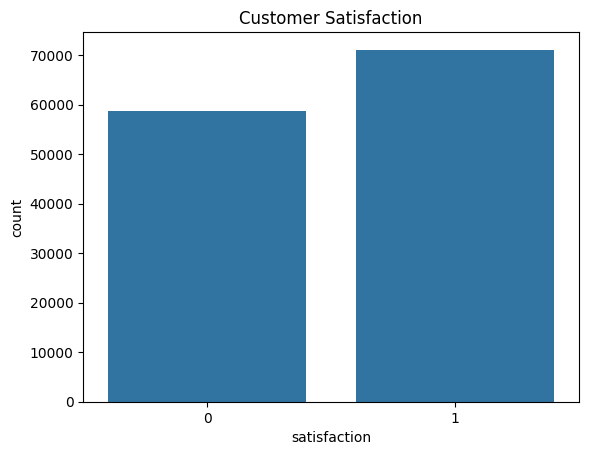

In [19]:
sns.countplot( x = 'satisfaction' , data= df)
plt.title('Customer Satisfaction')
plt.show()

In [20]:
df['satisfaction'].value_counts()

satisfaction
1    71087
0    58793
Name: count, dtype: int64

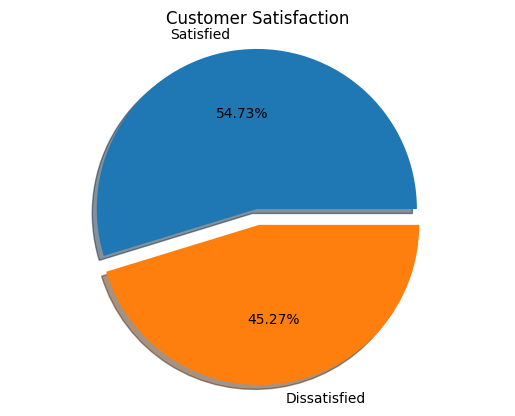

In [21]:
plt.pie(df['satisfaction'].value_counts() , 
        labels = ('Satisfied','Dissatisfied') , 
        autopct = '%1.2f%%' , 
        shadow = True , 
        explode = [0 , 0.1])
plt.title('Customer Satisfaction')
plt.axis('equal')
plt.show()

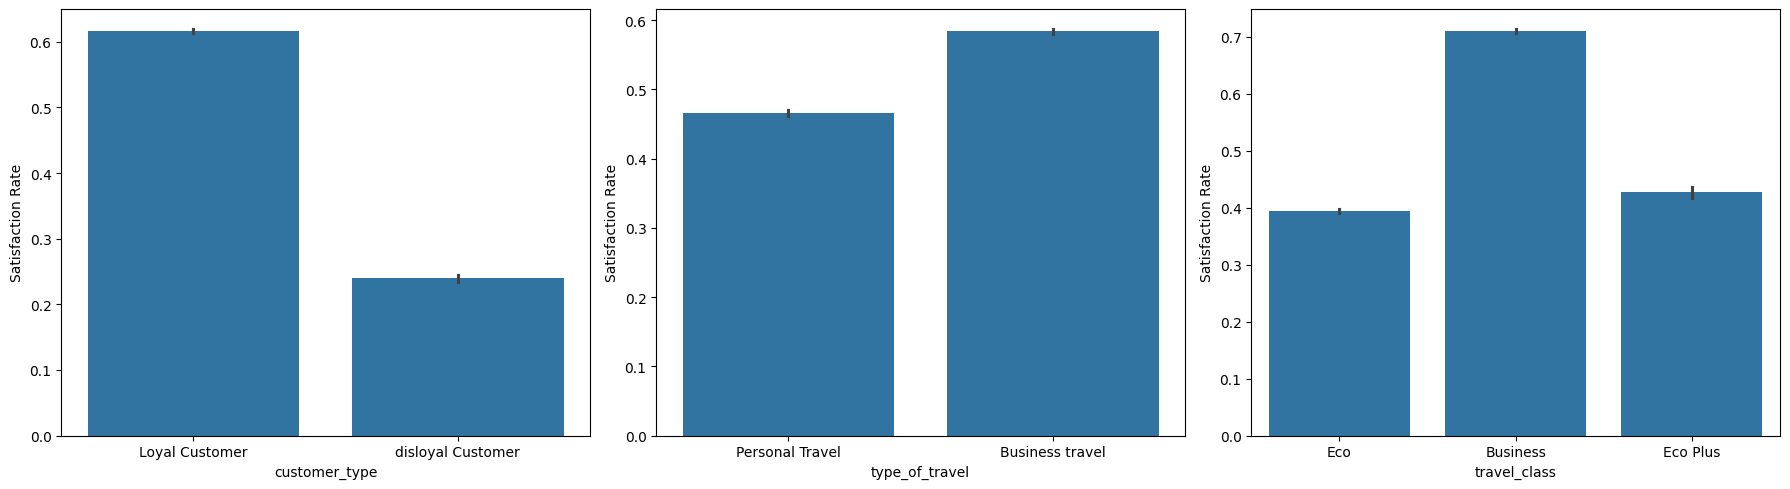

In [22]:
cat_cols = ['customer_type' , 'type_of_travel' , 'travel_class']

plt.figure(figsize= (18, 5))
for i, col in enumerate(cat_cols):
    plt.subplot(1, 3, i + 1)
    sns.barplot(x= col , y= 'satisfaction' , data= df)
    plt.ylabel('Satisfaction Rate')
plt.tight_layout()
plt.show()

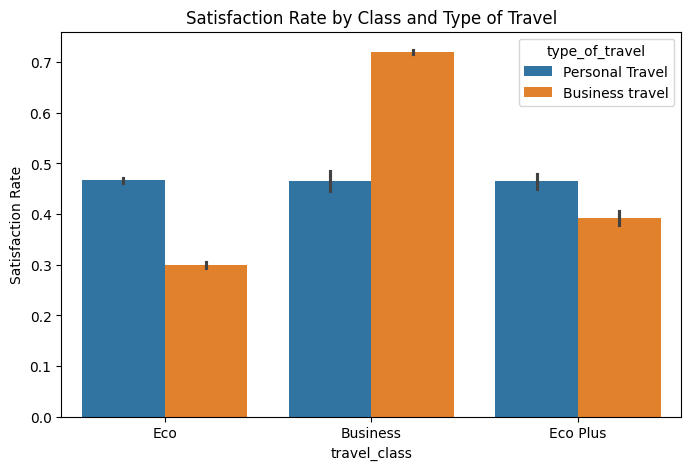

In [23]:
plt.figure(figsize= (8,5))
plt.title('Satisfaction Rate by Class and Type of Travel')
sns.barplot( x = 'travel_class' , y= 'satisfaction' , hue= 'type_of_travel' , data= df)
plt.ylabel('Satisfaction Rate')
plt.show()

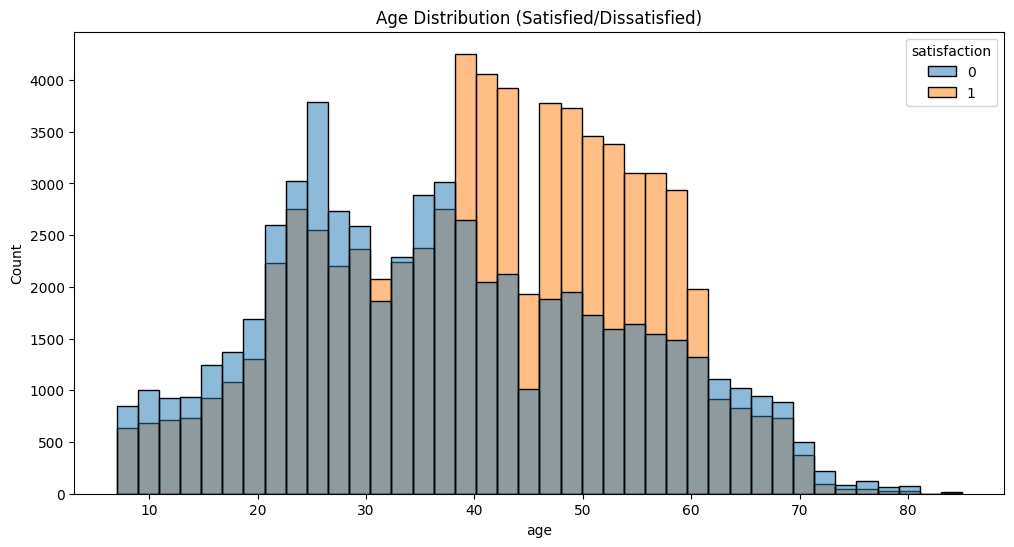

In [24]:
plt.figure(figsize=(12, 6))
plt.title('Age Distribution (Satisfied/Dissatisfied)')
sns.histplot(data=df , x='age' , bins= 40 , hue= 'satisfaction')
plt.show()

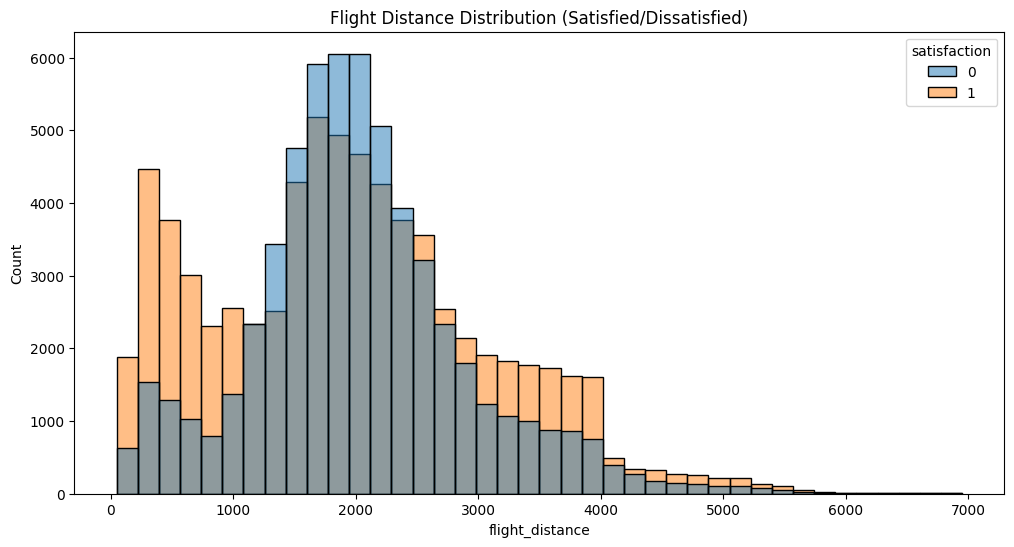

In [25]:
plt.figure(figsize=(12, 6))
plt.title('Flight Distance Distribution (Satisfied/Dissatisfied)')
sns.histplot(data=df , x='flight_distance' , bins= 40 , hue= 'satisfaction')
plt.show()

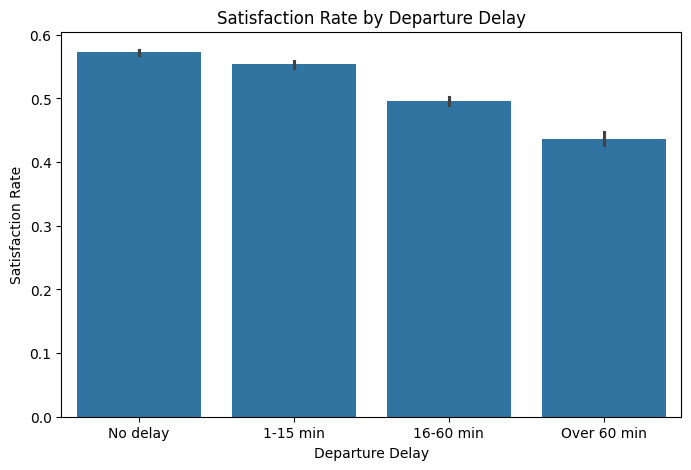

In [26]:
plt.figure(figsize= (8,5))
plt.title('Satisfaction Rate by Departure Delay')
sns.barplot( x = pd.cut(df['departure_delay_in_minutes'] , bins= [-1 , 0 , 15 , 60 , 2000] , labels= ['No delay' , '1-15 min' , '16-60 min' , 'Over 60 min']) , y= df['satisfaction'])
plt.xlabel('Departure Delay')
plt.ylabel('Satisfaction Rate')
plt.show()

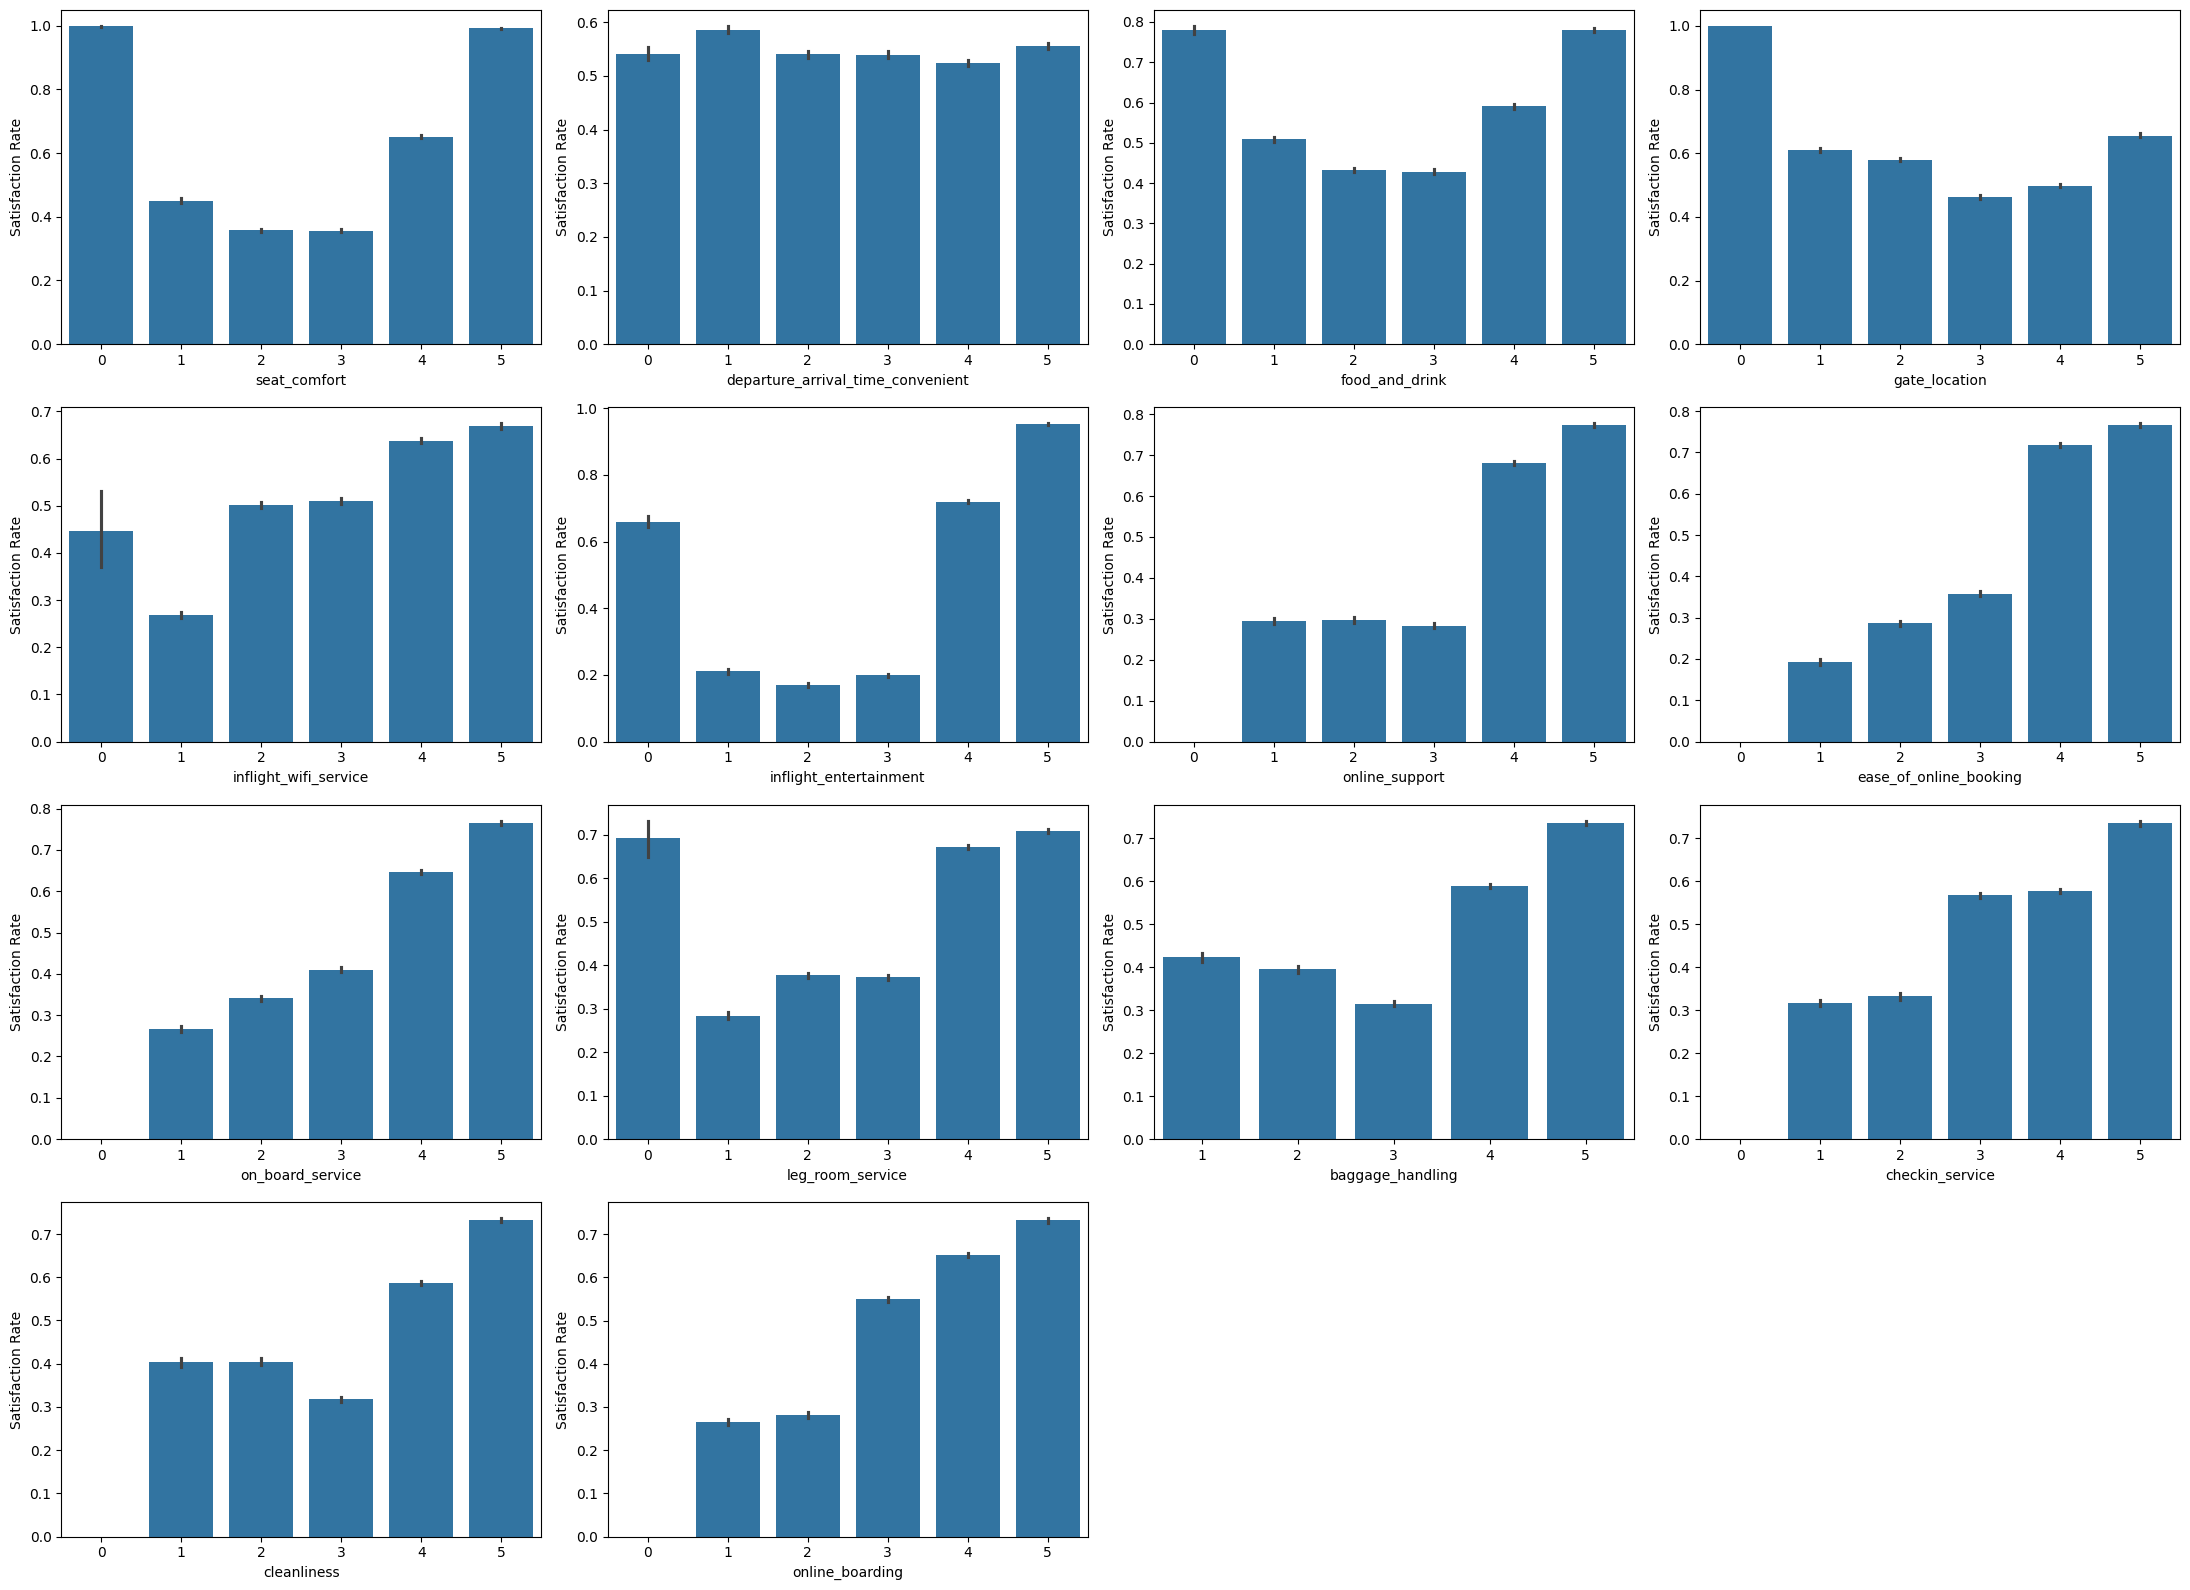

In [27]:
plt.figure(figsize= (22, 16))
for i, col in enumerate(rating_cols):
    plt.subplot(4, 4, i + 1)
    sns.barplot(x= col , y= 'satisfaction' , data= df)
    plt.ylabel('Satisfaction Rate')
plt.tight_layout()
plt.show()

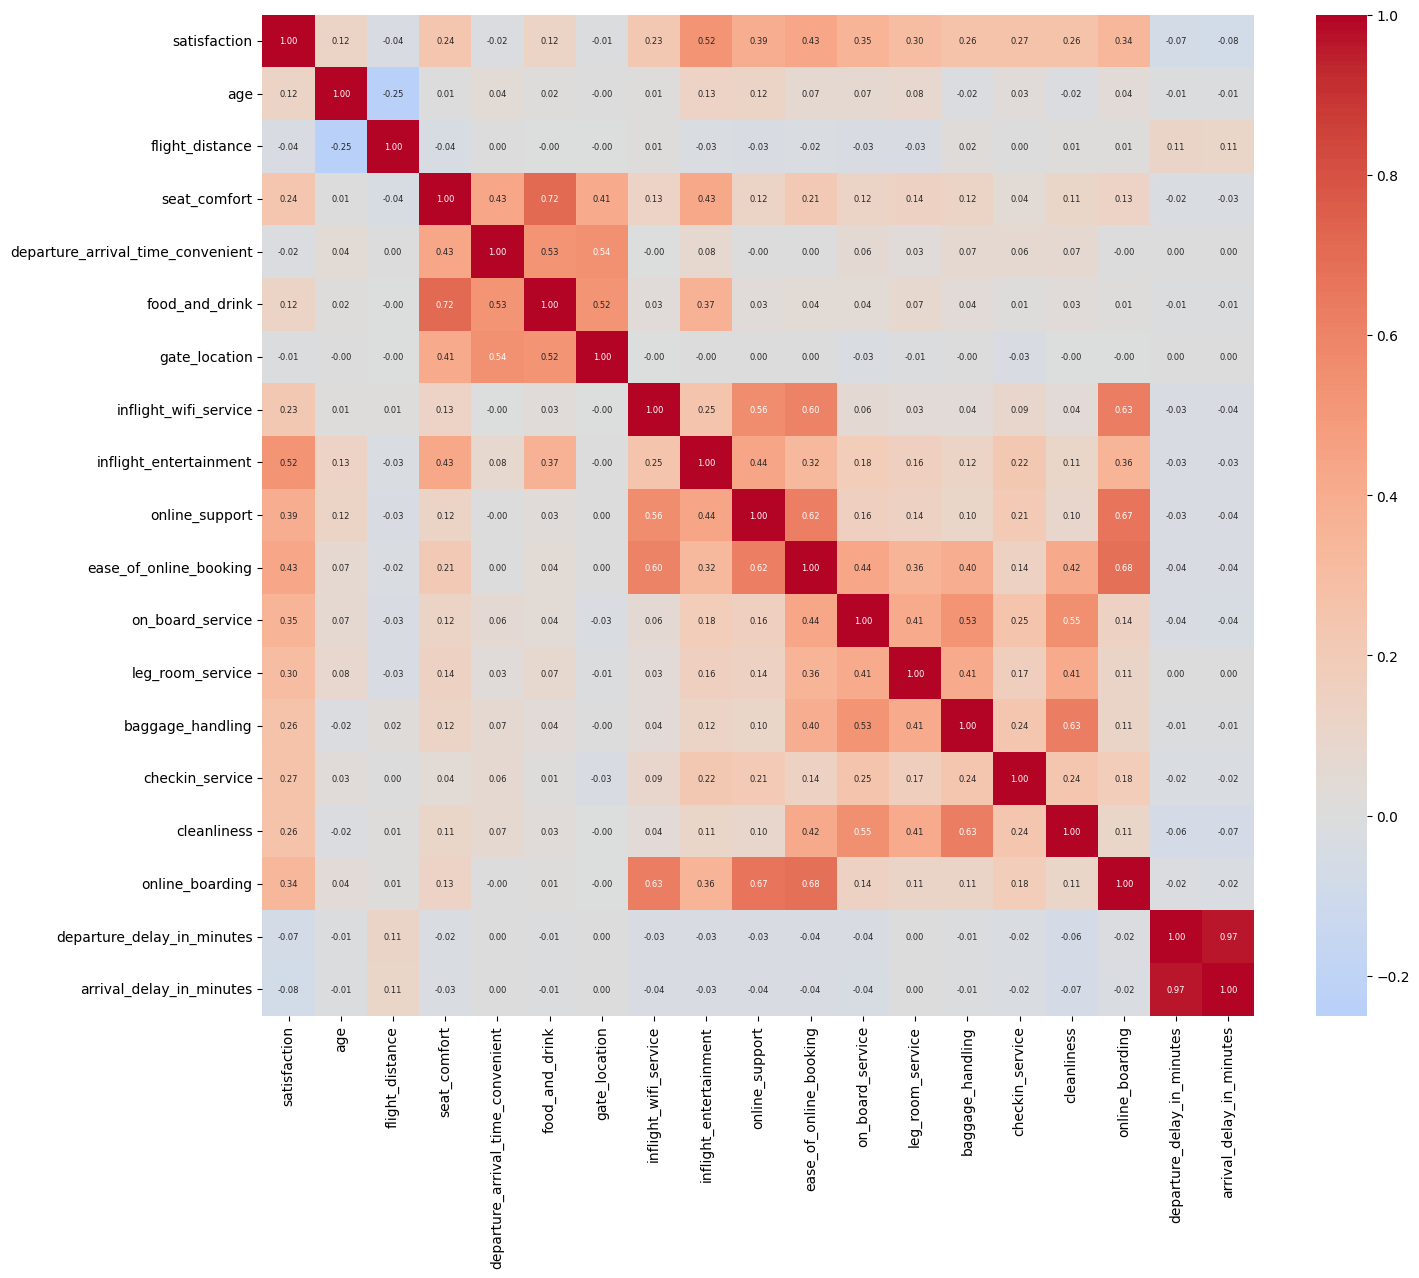

In [28]:
plt.figure(figsize= (16,13))
sns.heatmap (df.corr(numeric_only= True) , annot= True , fmt= '.2f' , annot_kws= {'size': 6} , cmap= 'coolwarm' , center= 0)
plt.show()

In [29]:
df.corr(numeric_only= True)['satisfaction'].drop('satisfaction').sort_values(ascending= False)

inflight_entertainment               0.523496
ease_of_online_booking               0.431772
online_support                       0.390143
on_board_service                     0.352047
online_boarding                      0.338147
leg_room_service                     0.304928
checkin_service                      0.266179
baggage_handling                     0.260347
cleanliness                          0.259330
seat_comfort                         0.242384
inflight_wifi_service                0.227062
food_and_drink                       0.120677
age                                  0.117971
gate_location                       -0.012071
departure_arrival_time_convenient   -0.015507
flight_distance                     -0.039224
departure_delay_in_minutes          -0.073909
arrival_delay_in_minutes            -0.080601
Name: satisfaction, dtype: float64

In [30]:
X = df.drop(columns= 'satisfaction')
y = df['satisfaction']

In [31]:
cat_features = ['customer_type' , 'type_of_travel' , 'travel_class']
delay_features = ['departure_delay_in_minutes' , 'arrival_delay_in_minutes']
num_features = ['age' , 'flight_distance'] + rating_cols

In [32]:
preprocessor = ColumnTransformer([
    ('delay' , Pipeline([('log' , FunctionTransformer(np.log1p)) , ('scale' , StandardScaler())]) , delay_features) ,
    ('num' , StandardScaler() , num_features) ,
    ('cat' , OneHotEncoder(drop= 'if_binary' , handle_unknown= 'ignore') , cat_features)
])

### **Train Test Split**

In [33]:
X_train , X_test , y_train , y_test = train_test_split(X , y , test_size= 0.2 , random_state= 42 , stratify= y)

In [34]:
X_train.shape , X_test.shape

((103904, 21), (25976, 21))

In [35]:
y_train.mean() , y_test.mean()

(np.float64(0.5473321527563905), np.float64(0.5473129042192794))

### **Model Training**

In [36]:
models = {
    'Logistic Regression': LogisticRegression(max_iter= 1000) ,
    'Random Forest': RandomForestClassifier(n_estimators= 100 , random_state= 42 , n_jobs= -1) ,
    'Hist Gradient Boosting': HistGradientBoostingClassifier(random_state= 42)
}

cv = StratifiedKFold(n_splits= 3 , shuffle= True , random_state= 42)

In [37]:
scores = {}
metrics = ['roc_auc' , 'recall' , 'precision' , 'f1' , 'accuracy']
for name, model in models.items():
    pipe = Pipeline([('preprocessor' , preprocessor) , ('model' , model)])
    result = cross_validate(pipe , X_train , y_train , cv= cv , scoring= metrics)
    scores[name] = {metric: result['test_' + metric].mean() for metric in metrics}

baseline = pd.DataFrame(scores).T.sort_values('roc_auc' , ascending= False)
baseline.round(4)

,roc_auc,recall,precision,f1,accuracy
Hist Gradient Boosting,0.9919,0.9470,0.9633,0.9551,0.9513
Random Forest,0.9916,0.9486,0.9638,0.9561,0.9524
Logistic Regression,0.9032,0.8457,0.8439,0.8448,0.8299


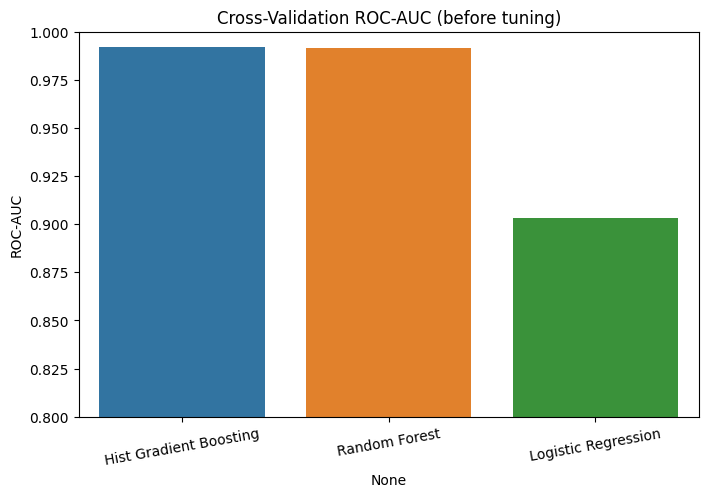

In [38]:
plt.figure(figsize= (8,5))
plt.title('Cross-Validation ROC-AUC (before tuning)')
sns.barplot( x = baseline.index , y= baseline['roc_auc'] , hue= baseline.index)
plt.ylabel('ROC-AUC')
plt.ylim(0.8 , 1)
plt.xticks(rotation= 10)
plt.show()

In [39]:
param_grids = {
    'Logistic Regression': {'model__C': [0.1 , 1 , 10]} ,
    'Random Forest': {'model__max_depth': [15 , None] , 'model__min_samples_leaf': [1 , 3]} ,
    'Hist Gradient Boosting': {'model__learning_rate': [0.1 , 0.2 , 0.3] , 'model__max_leaf_nodes': [63 , 127]}
}

grid_results = {}
for name, grid in param_grids.items():
    pipe = Pipeline([('preprocessor' , preprocessor) , ('model' , models[name])])
    grid_results[name] = GridSearchCV(pipe , grid , cv= cv , scoring= 'roc_auc' , n_jobs= -1).fit(X_train , y_train)
    print(name , round(grid_results[name].best_score_ , 4) , grid_results[name].best_params_)

Logistic Regression 0.9032 {'model__C': 0.1}
Random Forest 0.9916 {'model__max_depth': None, 'model__min_samples_leaf': 1}
Hist Gradient Boosting 0.9936 {'model__learning_rate': 0.1, 'model__max_leaf_nodes': 127}


In [40]:
best_name = max(grid_results , key= lambda name: grid_results[name].best_score_)
final_model = grid_results[best_name].best_estimator_
best_name

'Hist Gradient Boosting'

### **Model Evaluation**

In [41]:
y_pred = final_model.predict(X_test)
y_prob = final_model.predict_proba(X_test)[: , 1]

print(classification_report(y_test , y_pred , target_names= ['Dissatisfied' , 'Satisfied'] , digits= 3))

              precision    recall  f1-score   support

Dissatisfied      0.941     0.968     0.954     11759
   Satisfied      0.973     0.949     0.961     14217

    accuracy                          0.958     25976
   macro avg      0.957     0.959     0.958     25976
weighted avg      0.958     0.958     0.958     25976



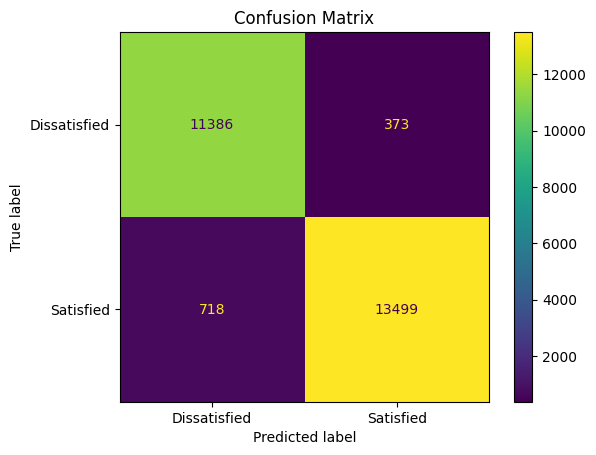

In [42]:
ConfusionMatrixDisplay.from_predictions(y_test , y_pred , display_labels= ['Dissatisfied' , 'Satisfied'])
plt.title('Confusion Matrix')
plt.show()

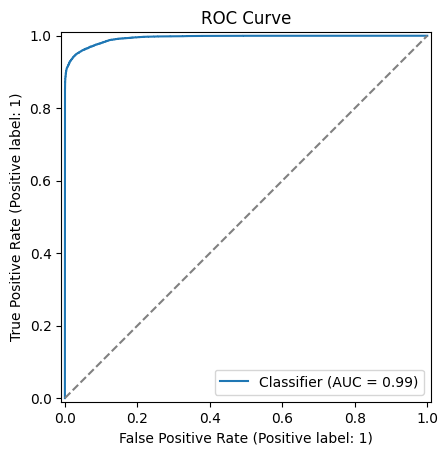

In [43]:
RocCurveDisplay.from_predictions(y_test , y_prob)
plt.plot([0 , 1] , [0 , 1] , ls= '--' , color= 'gray')
plt.title('ROC Curve')
plt.show()

In [44]:
roc_auc_score(y_test , y_prob)

0.9940813817737405

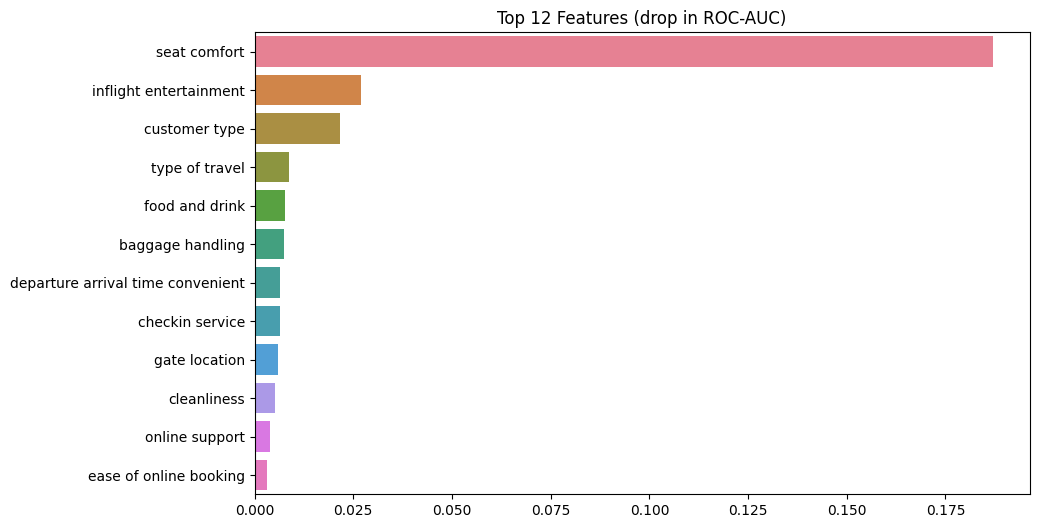

In [45]:
importance = permutation_importance(final_model , X_test , y_test , scoring= 'roc_auc' , n_repeats= 5 , random_state= 42 , n_jobs= -1)
importance_df = pd.Series(importance.importances_mean , index= X_test.columns).sort_values(ascending= False).head(12)
importance_df.index = importance_df.index.str.replace('_' , ' ')

plt.figure(figsize= (10,6))
plt.title('Top 12 Features (drop in ROC-AUC)')
sns.barplot( x = importance_df.values , y= importance_df.index , hue= importance_df.index)
plt.ylabel('')
plt.show()